# Receipt Expense Tracker

Reads photos of shop receipts with the Gemini API, checks that the prices add up to the total, saves the items to a CSV table and draws spending charts. Gemini also writes a short spending summary.

Setup: add your Gemini API key to Colab Secrets as GEMINI_API_KEY, then Runtime -> Run all.

## Overview

The notebook follows the sequence diagram in the README: load the receipts, Gemini reads each photo, the validator checks the total, the items are saved to expenses.csv, then the charts and the Gemini summary.

## 1. Setup

In [1]:
!pip install -q google-genai

import json
import time
from typing import Literal, Optional

import matplotlib.pyplot as plt
import pandas as pd
from google import genai
from google.genai import types
from IPython.display import Markdown
from PIL import Image, ImageOps
from pydantic import BaseModel

In [2]:
from google.colab import userdata

client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
MODELS = ["gemini-flash-latest", "gemini-flash-lite-latest"]

# the free tier is often overloaded, so retry and switch between the two models
def ask_gemini(contents, config=None):
    for attempt in range(6):
        model = MODELS[attempt % 2]
        try:
            return client.models.generate_content(model=model, contents=contents, config=config)
        except Exception as error:
            if attempt == 5:
                raise
            print(f"{model}: {error}, retrying in 10 s...")
            time.sleep(10)

## 2. Load data from GitHub

Downloads the repo with the receipt photos and the prompt.

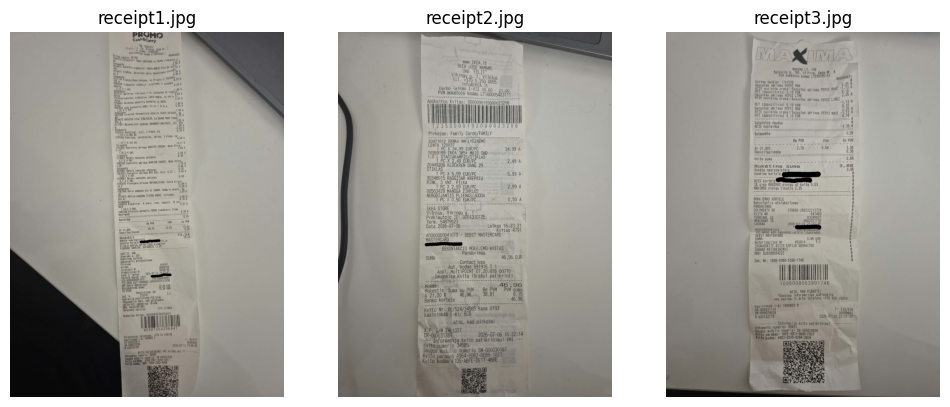

In [3]:
!git clone -q https://github.com/domantasmik/receipt-expense-tracker
REPO = "receipt-expense-tracker"

with open(f"{REPO}/prompts/prompt.json", encoding="utf-8") as f:
    PROMPT = json.load(f)
with open(f"{REPO}/data/examples.json", encoding="utf-8") as f:
    EXAMPLES = json.load(f)

def load_image(file_name):
    # fix rotation of phone photos
    return ImageOps.exif_transpose(Image.open(f"{REPO}/data/{file_name}"))

fig, axes = plt.subplots(1, len(EXAMPLES), figsize=(12, 6))
for ax, example in zip(axes, EXAMPLES):
    ax.imshow(load_image(example["X"]))
    ax.set_title(example["X"])
    ax.axis("off")
plt.show()

## 3. Output schema

The JSON format Gemini has to return. Discounts are items with a negative price.

In [4]:
class Item(BaseModel):
    name: str
    price: float
    category: Literal["food", "drinks", "snacks", "household", "hygiene", "alcohol", "discount", "other"]

class Receipt(BaseModel):
    shop: str
    date: Optional[str]  # YYYY-MM-DD, null if unreadable
    items: list[Item]
    total: float

## 4. Reading a receipt with Gemini

Sends the photo and the prompt to Gemini and gets the receipt back as JSON.

In [5]:
def extract_receipt(file_name):
    response = ask_gemini(
        [load_image(file_name), PROMPT["user_prompt"]],
        types.GenerateContentConfig(
            system_instruction=PROMPT["system_prompt"],
            temperature=0,
            response_mime_type="application/json",
            response_schema=Receipt,
        ),
    )
    return json.loads(response.text)

## 5. Receipt Validator

Checks that the item prices add up to the total. If not, the receipt is marked needs review.

In [6]:
def validate(receipt):
    items_sum = round(sum(item["price"] for item in receipt["items"]), 2)
    difference = round(items_sum - receipt["total"], 2)
    status = "ok" if abs(difference) <= 0.02 else "needs review"
    return {"items_sum": items_sum, "difference": difference, "status": status}

## 6. Running all receipts

Reads and checks every receipt, then saves all items to expenses.csv.

In [7]:
rows = []

for example in EXAMPLES:
    receipt = extract_receipt(example["X"])
    check = validate(receipt)
    print(example["id"], receipt["shop"], check)
    for item in receipt["items"]:
        rows.append({"receipt": example["id"], "shop": receipt["shop"], "date": receipt["date"],
                     **item, "status": check["status"]})

expenses = pd.DataFrame(rows)
expenses.to_csv("expenses.csv", index=False)
expenses

gemini-flash-latest: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}, retrying in 10 s...
receipt_01 PROMO Cash&Carry {'items_sum': 75.66, 'difference': 2.42, 'status': 'needs review'}
gemini-flash-latest: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 12h15m36.682521518s.', 'status': 'RESOURCE_EXHAUSTED', 'detai

,receipt,shop,date,name,price,category,status
0,receipt_01,PROMO Cash&Carry,2026-07-22,Ledai SNICKERS su žemės riešutais,1.29,snacks,needs review
1,receipt_01,PROMO Cash&Carry,2026-07-22,Sutaupote,-0.42,discount,needs review
2,receipt_01,PROMO Cash&Carry,2026-07-22,Kukurūzų traškučiai SANTA MARIA Pico De Gallo 185,2.51,snacks,needs review
3,receipt_01,PROMO Cash&Carry,2026-07-22,"Traškūs, džiovinto sūrio kamuoliukai azijos sk...",1.99,snacks,needs review
4,receipt_01,PROMO Cash&Carry,2026-07-22,Sutaupote,-0.50,discount,needs review
5,receipt_01,PROMO Cash&Carry,2026-07-22,"Prancūziškas batonėlis, su sviestu ir česnaku,",0.79,food,needs review
6,receipt_01,PROMO Cash&Carry,2026-07-22,Traškučiai ESTRELLA griežinėlių ir svogūnų 4x65g,4.24,snacks,needs review
7,receipt_01,PROMO Cash&Carry,2026-07-22,Sutaupote,-1.86,discount,needs review
8,receipt_01,PROMO Cash&Carry,2026-07-22,Šaldytos vištienos file juostelės su traškiu d...,6.69,food,needs review
9,receipt_01,PROMO Cash&Carry,2026-07-22,"Kukurūzų traškučiai SANTA MARIA, su sūriu ir J...",2.51,snacks,needs review


JSON returned for the last receipt:

In [8]:
print(json.dumps(receipt, ensure_ascii=False, indent=2))

{
  "shop": "MAXIMA",
  "date": "2026-07-22",
  "items": [
    {
      "name": "Gazuotas gėrimas PEPSI MAX",
      "price": 2.25,
      "category": "drinks"
    },
    {
      "name": "AČIŪ nuolaida prekei: Gazuotas gėrimas PEPSI MAX",
      "price": -1.13,
      "category": "discount"
    },
    {
      "name": "PET (depozitinis) 0,10 EUR",
      "price": 0.1,
      "category": "other"
    },
    {
      "name": "Gazuotas gėrimas PEPSI LIME",
      "price": 2.25,
      "category": "drinks"
    },
    {
      "name": "AČIŪ nuolaida prekei: Gazuotas gėrimas PEPSI LIME",
      "price": -1.13,
      "category": "discount"
    },
    {
      "name": "PET (depozitinis) 0,10 EUR",
      "price": 0.1,
      "category": "other"
    },
    {
      "name": "Gazuotas gėrimas PEPSI MAX",
      "price": 2.25,
      "category": "drinks"
    },
    {
      "name": "AČIŪ nuolaida prekei: Gazuotas gėrimas PEPSI MAX",
      "price": -1.13,
      "category": "discount"
    },
    {
      "name": "PET (de

## 7. Charts

Spending by category (before discounts) and by shop (amount paid).

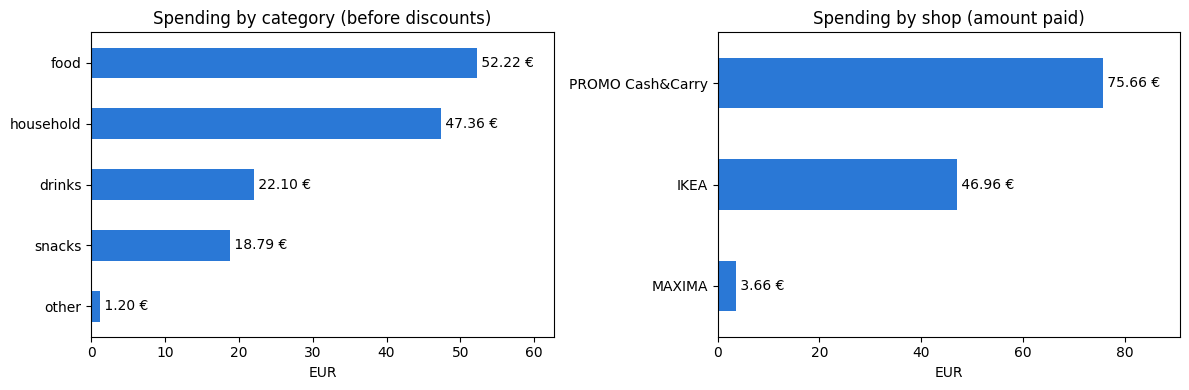

Total paid: 126.28 EUR, saved with discounts: 15.39 EUR


In [9]:
by_category = expenses[expenses["category"] != "discount"].groupby("category")["price"].sum()
by_shop = expenses.groupby("shop")["price"].sum()
saved = -expenses[expenses["category"] == "discount"]["price"].sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, title in [(ax1, by_category, "Spending by category (before discounts)"),
                          (ax2, by_shop, "Spending by shop (amount paid)")]:
    values.sort_values().plot.barh(ax=ax, color="#2a78d6", title=title, xlabel="EUR", ylabel="")
    ax.bar_label(ax.containers[0], fmt=" %.2f €")
    ax.margins(x=0.2)
plt.tight_layout()
plt.show()

print(f"Total paid: {expenses['price'].sum():.2f} EUR, saved with discounts: {saved:.2f} EUR")

## 8. Spending summary

Gemini writes a short summary from the totals.

In [10]:
totals = {
    "total_paid_eur": round(expenses["price"].sum(), 2),
    "saved_with_discounts_eur": round(saved, 2),
    "by_category_eur": by_category.round(2).to_dict(),
    "by_shop_eur": by_shop.round(2).to_dict(),
}

summary_prompt = (
    f"Here are my expenses from shop receipts: {json.dumps(totals)}\n"
    "Write a short spending summary (4-5 sentences): how much I spent, the biggest categories, "
    "how much the discounts saved, and one practical tip. Use only these numbers."
)

response = ask_gemini(summary_prompt)
Markdown(response.text)

gemini-flash-latest: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 12h15m10.992381174s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'description': 'Generate content requests per day limit exceeded on Free Tier

You spent a total of 126.28 EUR across your shopping trips. Your biggest spending categories were food at 52.22 EUR and household items at 47.36 EUR. Smart shopping helped you save 15.39 EUR with discounts. Since PROMO Cash&Carry was your largest expense at 75.66 EUR, consider buying household essentials in bulk there less frequently to better manage your budget.